# 🔍 **Практический разбор EDA (Exploratory Data Analysis)**

**Датасет:** Steel Industry Energy Consumption
https://archive.ics.uci.edu/dataset/851/steel+industry+energy+consumption

**Бизнес-задача:** Прогнозирование энергопотребления металлургического завода

***Описание*** Требуется спрогнозировать активную мощность энергопотребления завода по 15-ти минутным интервалам на основе показателей реактивной мощности, коэффициента нагрузки, выбросов CO2 и календарного графика

#Первичный осмотр данных

In [6]:
# установка пакета ucimlrepo
!pip3 install -U ucimlrepo


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Импорт основных библиотек и функций для работы с данными
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi
from pprint import pprint
from ucimlrepo import fetch_ucirepo

## 1. Описание датасета

In [14]:
# загрузка датасета
energy_data = fetch_ucirepo(id=851)
# вывод датасета
pprint(energy_data)

{'data': {'features':        Usage_kWh  Lagging_Current_Reactive.Power_kVarh  \
0           3.17                                  2.95   
1           4.00                                  4.46   
2           3.24                                  3.28   
3           3.31                                  3.56   
4           3.82                                  4.50   
...          ...                                   ...   
35035       3.85                                  4.86   
35036       3.74                                  3.74   
35037       3.78                                  3.17   
35038       3.78                                  3.06   
35039       3.67                                  3.02   

       Leading_Current_Reactive_Power_kVarh  CO2(tCO2)  \
0                                      0.00        0.0   
1                                      0.00        0.0   
2                                      0.00        0.0   
3                                      0.00      

Видим, что наш датасет имеет структуру вложенных словарей под ключом data из признаков - features, и заголовков - headers. Сохраним в переменную df датасет из ключа data и посмотри его структуру

In [15]:
df = energy_data.data
for key in df.keys():
  print(key)

ids
features
targets
original
headers


Датасет разбит на отдельные словари. Признаки для модели находятся в переменной features, метки классов при предсказании в переменной targets, оригинальный датасет в original, названия переменных в headers

Вектор признаков, которые потребуется предсказать, находится в переменной targets. Меток загрузки мощностей там три: легкая, средняя и максимальная

In [8]:
df.targets.sample(5, random_state=42)

,Load_Type
11356,Light_Load
26543,Maximum_Load
2445,Maximum_Load
14649,Light_Load
32699,Medium_Load


Признаки находятся в features. Из них числовых признаков семь и две текстовые метки, которые могут быть применены для анализа потребления мощностей в зависимости от рабочих дней недели

In [9]:
df.features.info()

<class 'pandas.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 9 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Usage_kWh                             35040 non-null  float64
 1   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 2   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 3   CO2(tCO2)                             35040 non-null  float64
 4   Lagging_Current_Power_Factor          35040 non-null  float64
 5   Leading_Current_Power_Factor          35040 non-null  float64
 6   NSM                                   35040 non-null  int64  
 7   WeekStatus                            35040 non-null  str    
 8   Day_of_week                           35040 non-null  str    
dtypes: float64(6), int64(1), str(2)
memory usage: 2.4 MB


Подробнее признаки, на которых будет происходить обучение модели, мы можем посмотреть через метод sample

In [48]:
# посмотрим образцы строк
df.features.sample(5, random_state=42)

,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week
11356,2.88,3.82,0.0,0.00,60.20,100.00,26100,Weekend,Sunday
26543,60.77,48.02,0.0,0.03,78.46,100.00,43200,Weekday,Thursday
2445,120.42,59.65,0.0,0.06,89.61,100.00,41400,Weekday,Friday
14649,3.13,0.00,16.6,0.00,100.00,18.53,52200,Weekend,Saturday
32699,58.86,20.99,0.0,0.03,94.19,100.00,54000,Weekday,Friday


Оригинальный датасет находится в original

In [29]:
df.original.info()

<class 'pandas.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 11 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   date                                  35040 non-null  str    
 1   Usage_kWh                             35040 non-null  float64
 2   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 3   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 4   CO2(tCO2)                             35040 non-null  float64
 5   Lagging_Current_Power_Factor          35040 non-null  float64
 6   Leading_Current_Power_Factor          35040 non-null  float64
 7   NSM                                   35040 non-null  int64  
 8   WeekStatus                            35040 non-null  str    
 9   Day_of_week                           35040 non-null  str    
 10  Load_Type                             35040 non-null  str    
dtypes: float64(6), int64(1), s

In [30]:
df.original.sample(8)

,date,Usage_kWh,Lagging_Current_Reactive.Power_kVarh,Leading_Current_Reactive_Power_kVarh,CO2(tCO2),Lagging_Current_Power_Factor,Leading_Current_Power_Factor,NSM,WeekStatus,Day_of_week,Load_Type
14672,02/06/2018 20:15,3.67,0.00,17.39,0.00,100.00,20.65,72900,Weekend,Saturday,Light_Load
9899,14/04/2018 03:00,3.71,4.50,0.00,0.00,63.61,100.00,10800,Weekend,Saturday,Light_Load
75,01/01/2018 19:00,4.07,0.00,22.57,0.00,100.00,17.75,68400,Weekday,Monday,Light_Load
10586,21/04/2018 06:45,2.92,3.71,0.00,0.00,61.85,100.00,24300,Weekend,Saturday,Light_Load
16297,19/06/2018 18:30,54.43,43.88,0.00,0.02,77.85,100.00,66600,Weekday,Tuesday,Medium_Load
5222,24/02/2018 09:45,51.30,4.03,2.23,0.02,99.69,99.91,35100,Weekend,Saturday,Medium_Load
9289,07/04/2018 18:30,3.85,0.00,7.38,0.00,100.00,46.25,66600,Weekend,Saturday,Medium_Load
9983,14/04/2018 00:00,3.02,3.20,0.00,0.00,68.64,100.00,0,Weekend,Saturday,Light_Load


## 2. Описание признаков

Согласно официальному описанию UCI, energy_data.data.features содержит 8 переменных, которые описывают энергопотребление, параметры электросети и временные метки металлургического завода. Они используются для анализа закономерностей энергопотребления, прогнозирования нагрузки или классификации.

### Usage_kWh

Общее потребление энергии заводом (в киловатт-часах).

### Lagging_Current_Reactive.Power_kVarh

Реактивная мощность запаздывающего тока (в киловольт-амперах реактивных часов). Отражает индуктивную нагрузку в электросети. В анализе часто выступает как важный признак, поскольку тесно связана с работой оборудования (например, двигателей).

### Leading_Current_Reactive_Power_kVarh

Реактивная мощность опережающего тока (квар·ч). Отражает емкостную нагрузку. Обычно используется вместе с предыдущей переменной для комплексной оценки качества электроэнергии и состояния оборудования.

### CO2(tCO2)

Выбросы углекислого газа (в частях на миллион). Используется для анализа воздействия энергопотребления на окружающую среду. Следует отметить, что в этом наборе данных значение данной переменной имеет низкое разрешение (мало уникальных значений), и ее прогностическая ценность для моделей может быть ограниченной.

### Lagging_Current_Power_Factor

Коэффициент мощности запаздывающего тока (в процентах). Показывает эффективность использования электроэнергии: чем выше значение, тем эффективнее используется мощность. Это ключевой показатель для оценки эффективности электросети.

### Leading_Current_Power_Factor

Коэффициент мощности опережающего тока (в процентах). Аналогичен предыдущему, но соответствует опережающему току. Используется для контроля состояния компенсирующих устройств или специфических нагрузок.

### NSM

Количество секунд от начала суток (Number of Seconds from Midnight). Временной признак, указывающий конкретное время суток (от 0 до 86400). Широко используется для моделирования суточных циклов энергопотребления на заводе, например, для выявления закономерностей запуска и остановки производства.

### WeekStatus

Тип дня недели: выходной или рабочий. Категориальная переменная, указывающая, является ли день выходным (Weekend) или рабочим днем (Weekday). Помогает модели различать кардинально разные режимы энергопотребления в рабочие и выходные дни.

### Day_of_week

Значение и назначение: День недели (от воскресенья до субботы). Более детальная временная классификация, чем WeekStatus, используется для анализа различий в энергопотреблении в разные дни недели (например, в понедельник может требоваться больше энергии для запуска оборудования).

Посмотрим переменную Usage_kWh в связи с типом загрузки

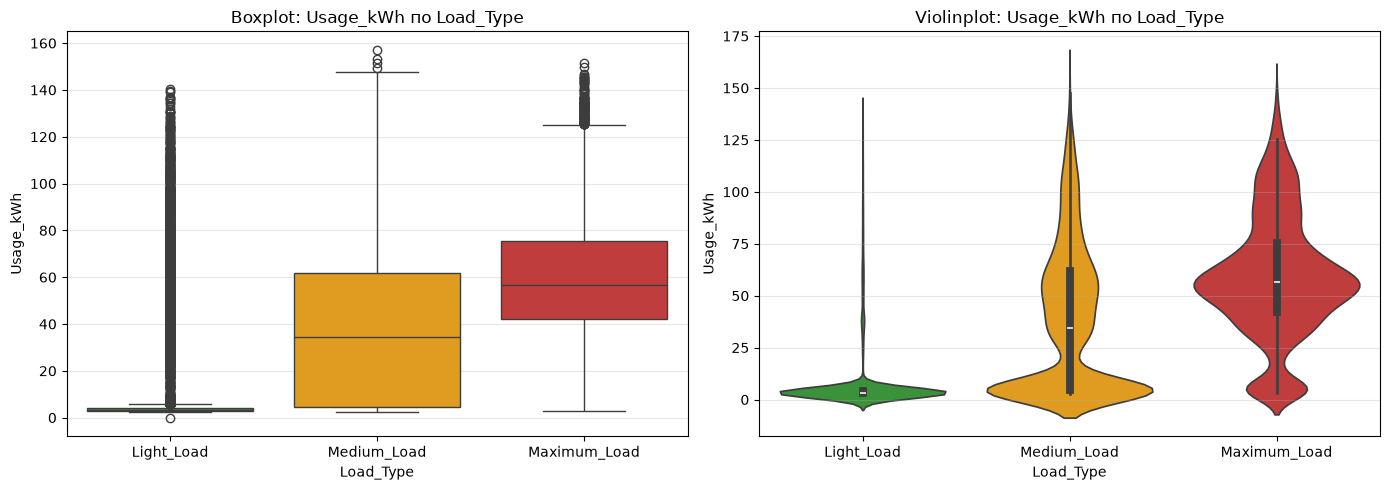

In [61]:
order = ['Light_Load', 'Medium_Load', 'Maximum_Load']
colors = {'Light_Load': '#2ca02c', 'Medium_Load': '#ffa600', 'Maximum_Load': '#d62728'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df.original, x='Load_Type', y='Usage_kWh', order=order,
            hue='Load_Type', palette=colors, ax=axes[0])
axes[0].set_title('Boxplot: Usage_kWh по Load_Type')
axes[0].grid(alpha=0.3, axis='y')

sns.violinplot(data=df.original, x='Load_Type', y='Usage_kWh', order=order,
               hue='Load_Type', palette=colors, ax=axes[1])
axes[1].set_title('Violinplot: Usage_kWh по Load_Type')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

In [58]:
df.original.groupby('Load_Type')['Usage_kWh'].describe().reindex(order)

,count,mean,std,min,25%,50%,75%,max
Load_Type,,,,,,,,
Light_Load,18072.0,8.626207,17.906245,0.00,2.9500,3.310,4.03,140.29
Medium_Load,9696.0,38.445394,35.220166,2.52,4.4200,34.435,61.70,157.18
Maximum_Load,7272.0,59.265314,29.749700,2.92,42.0025,56.630,75.31,151.67


# 3. Разведочный анализ данных (EDA)
Цель этого этапа — понять распределения, выбросы и взаимосвязи, особенно для целевой переменной Load_Type.

In [12]:
# Рассмотрим целевую переменную
print(df.targets.describe())

         Load_Type
count        35040
unique           3
top     Light_Load
freq         18072


По описанию колонки видно, что в ней 35040 значений трех типов. Самое часто встречающееся - Light_Load с частотой 18072

In [ ]:
# Выведем уникальные значения в колонке
print(df.targets['Load_Type'].unique())


['Light_Load' 'Medium_Load' 'Maximum_Load']


In [ ]:
# найдем пропущенные значения
print(df.targets['Load_Type'].isna().sum())

0


Для каждой строки проставлено одно из значений, пропусков нет.

Посмотрим наш оригинальный датасет и построим матрицу корреляций для него. Для начала осмотрим данные с помощью библиотеки seaborn, построив графики взаимосвязей признаков. Затем построим матрицу корреляций для них. Использовать будем оригинальный датасет под ключом original

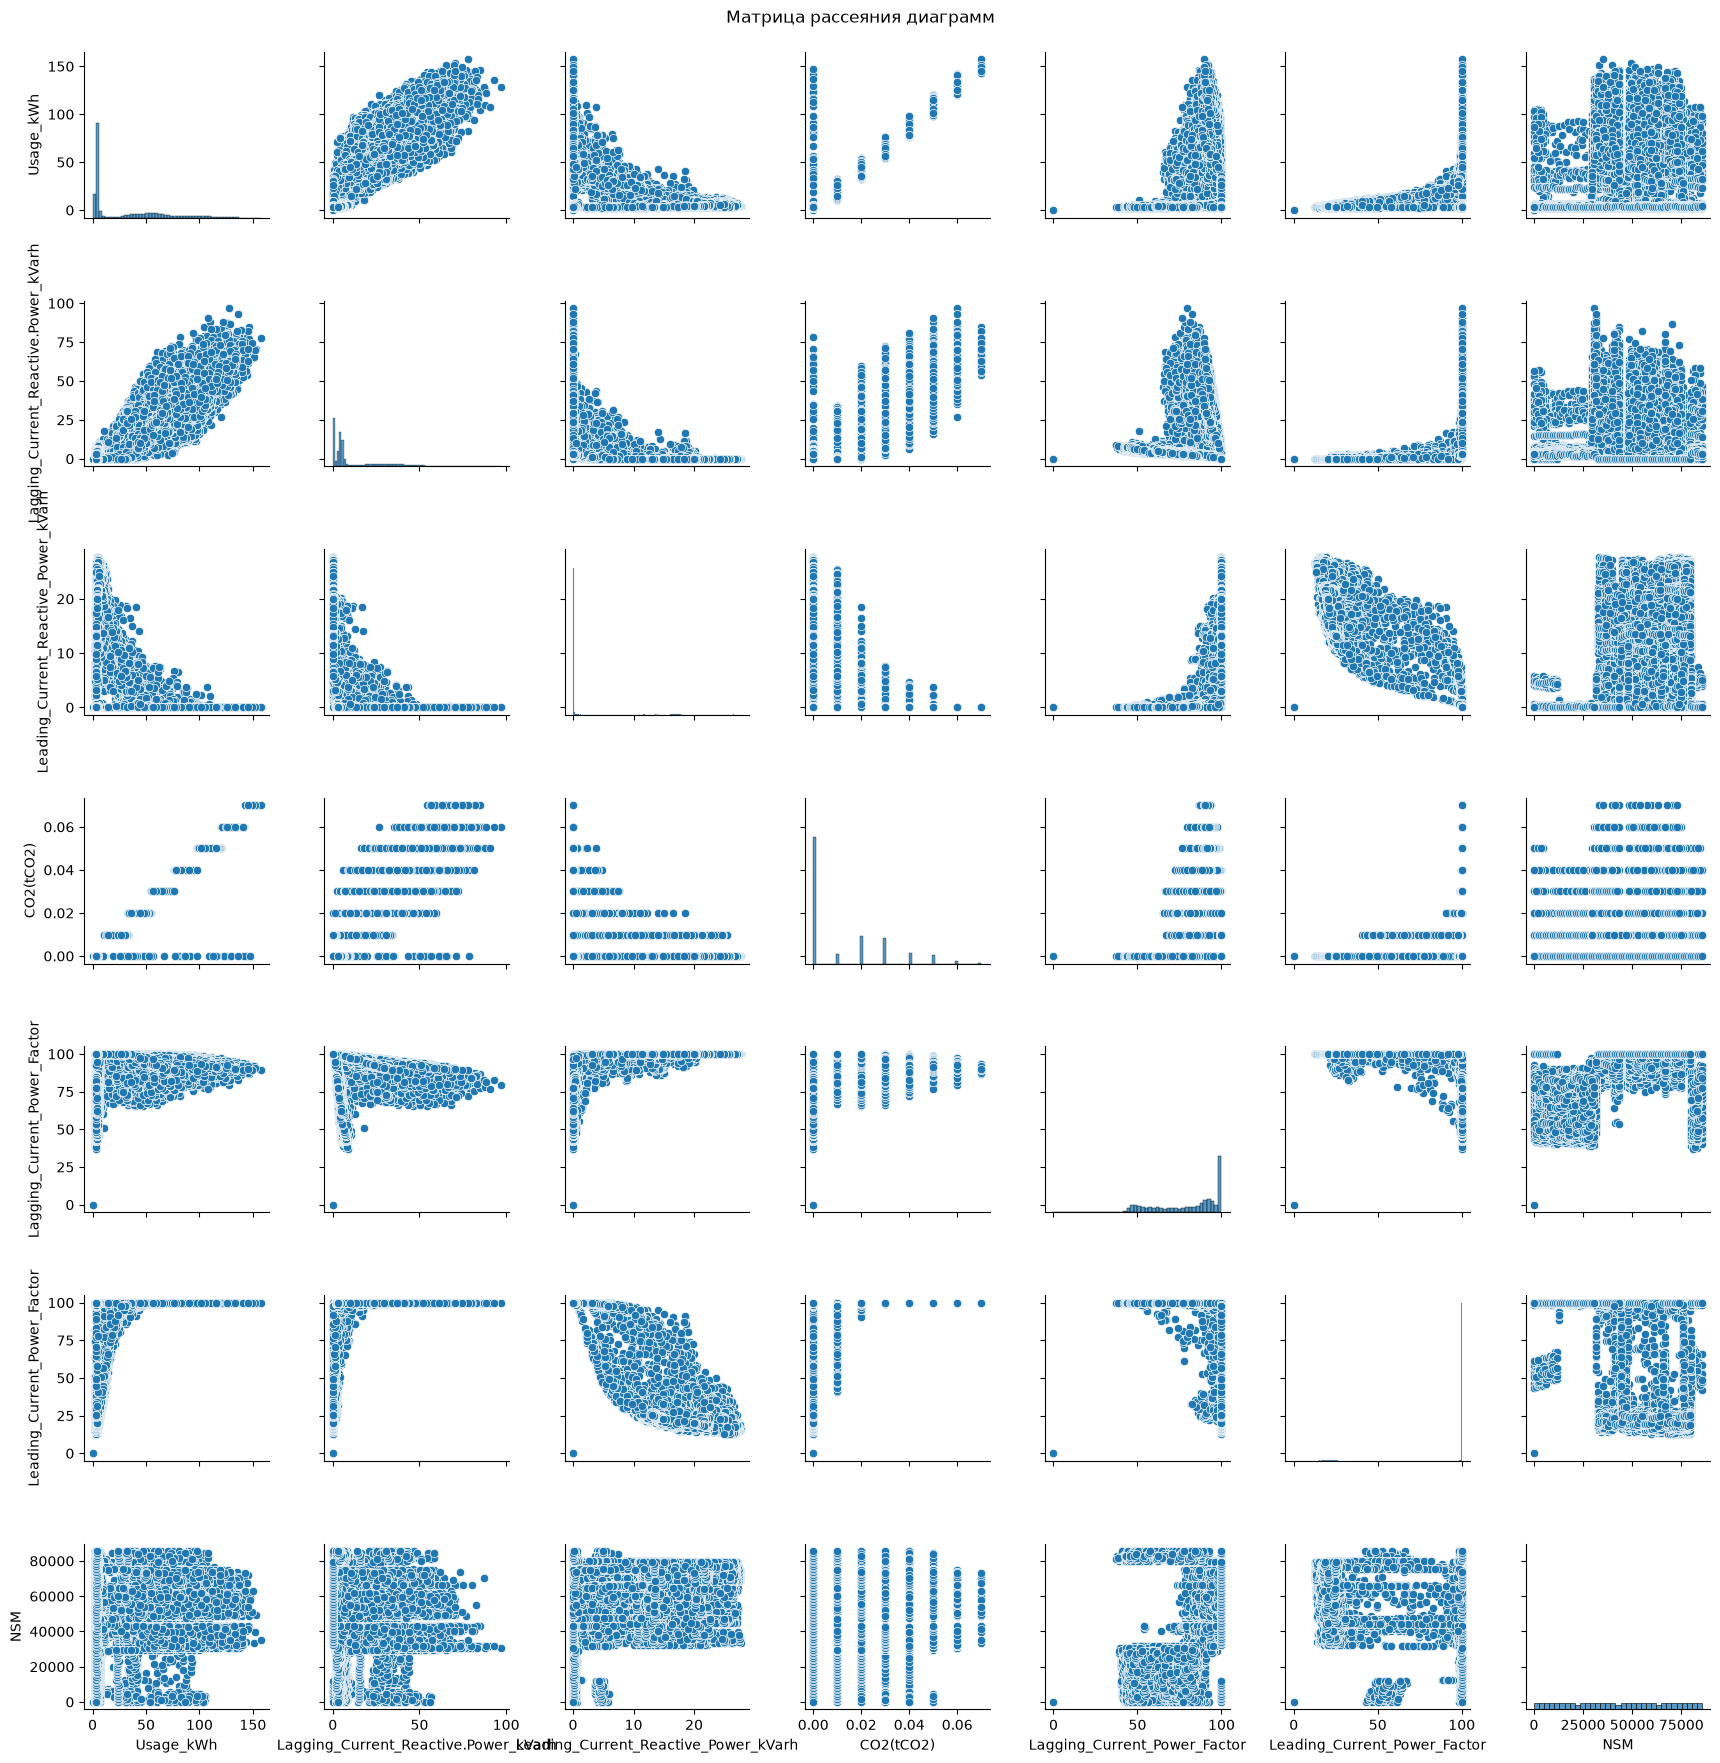

In [23]:
d = sns.pairplot(df.original, height=2.5)
d.figure.suptitle('Матрица рассеяния диаграмм', y=1.01)
d.figure.subplots_adjust(wspace=0.3, hspace=0.5)
plt.show()


Добавим матрицу корреляций

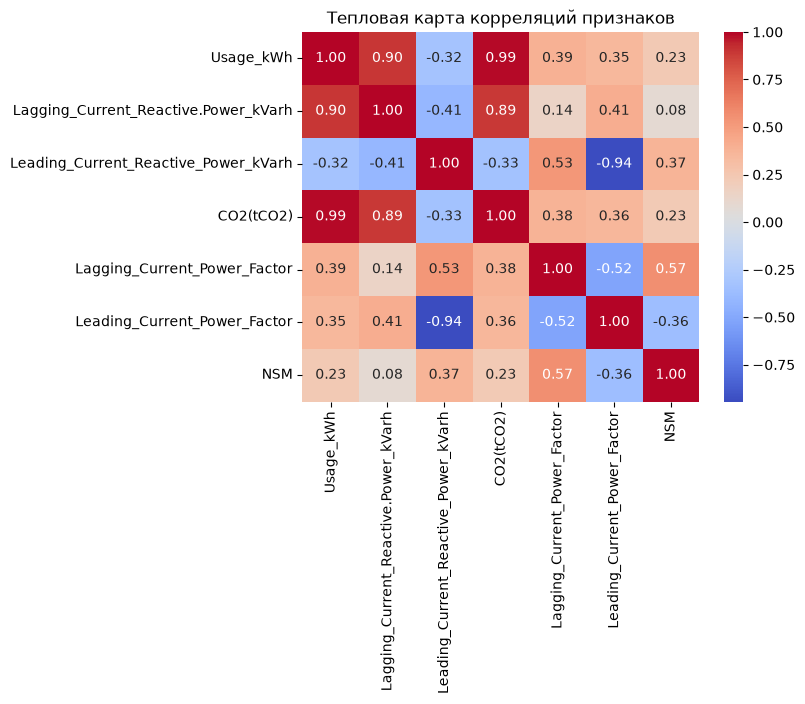

In [68]:
dfcm = df.original.drop(columns=['date', 'WeekStatus', 'Day_of_week', 'Load_Type'])
correlation_matrix = dfcm.corr()

plt.figure()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Тепловая карта корреляций признаков')
plt.show()

Теперь построим график распределения каждой из переменных по трем категориям из набора targets

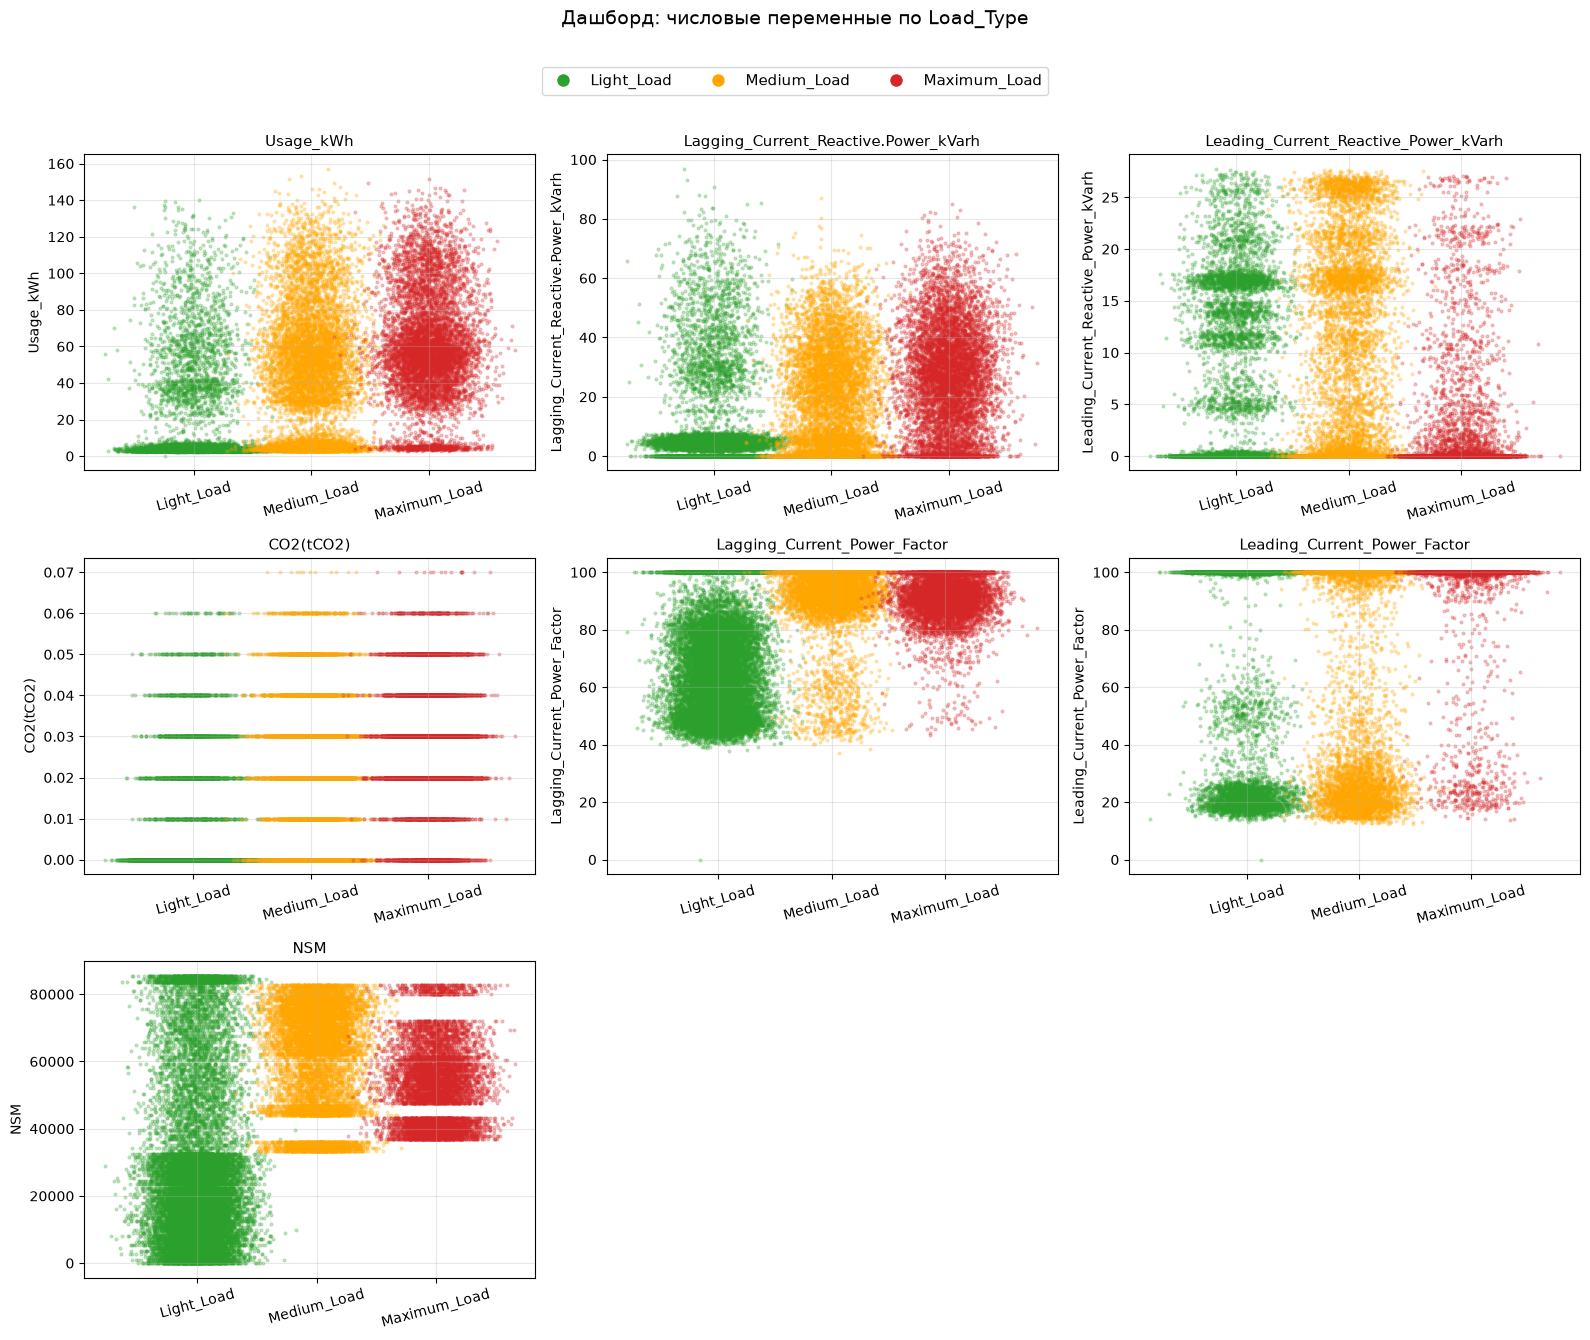

In [40]:
X = energy_data.data.features
y = energy_data.data.targets
all_data = X.join(y)

categories = ['Light_Load', 'Medium_Load', 'Maximum_Load']
colors = {
    'Light_Load':   '#2ca02c',   # зелёный
    'Medium_Load':  '#ffa600',   # жёлтый
    'Maximum_Load': '#d62728',   # красный
}

numeric_vars = [
    'Usage_kWh',
    'Lagging_Current_Reactive.Power_kVarh',
    'Leading_Current_Reactive_Power_kVarh',
    'CO2(tCO2)',
    'Lagging_Current_Power_Factor',
    'Leading_Current_Power_Factor',
    'NSM',
]

n = len(numeric_vars)
ncols = 3
nrows = int(np.ceil(n / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.2 * nrows))
axes = axes.flatten()

for ax, var in zip(axes, numeric_vars):
    for i, cat in enumerate(categories):
        subset = all_data[all_data['Load_Type'] == cat][var]
        x = i + np.random.normal(0, 0.2, size=len(subset))
        ax.scatter(x, subset, s=4, alpha=0.25, color=colors[cat], label=cat)

    ax.set_xticks(range(len(categories)))
    ax.set_xticklabels(categories, rotation=15)
    ax.set_title(var, fontsize=11)
    ax.set_ylabel(var)
    ax.grid(alpha=0.3)

for ax in axes[n:]:
    ax.set_visible(False)

handles = [plt.Line2D([0], [0], marker='o', color='w',
                      markerfacecolor=colors[c], markersize=10, label=c)
           for c in categories]
fig.legend(handles=handles, loc='upper center', ncol=3, fontsize=11,
           bbox_to_anchor=(0.5, 1.02))
fig.suptitle('Дашборд: числовые переменные по Load_Type', fontsize=14, y=1.06)
plt.tight_layout()
plt.show()

Мы ставим задачу прогнозирования типа загрузки электростанции. Подготовим переменные, на которых будем обучать модель.
Load_Type это категория, присвоенная по величине потребления. Признак Usage_kWh очень сильно связан с уровнем загрузки завода

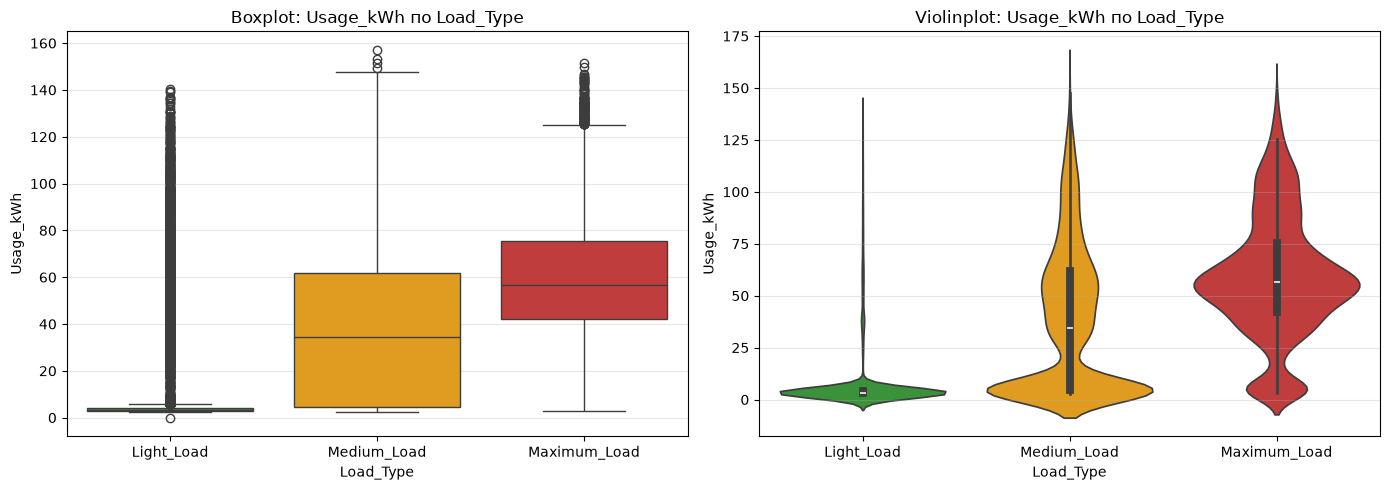

In [64]:
order = ['Light_Load', 'Medium_Load', 'Maximum_Load']
colors = {'Light_Load': '#2ca02c', 'Medium_Load': '#ffa600', 'Maximum_Load': '#d62728'}

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df.original, x='Load_Type', y='Usage_kWh', order=order,
            hue='Load_Type', palette=colors, ax=axes[0])
axes[0].set_title('Boxplot: Usage_kWh по Load_Type')
axes[0].grid(alpha=0.3, axis='y')

sns.violinplot(data=df.original, x='Load_Type', y='Usage_kWh', order=order,
               hue='Load_Type', palette=colors, ax=axes[1])
axes[1].set_title('Violinplot: Usage_kWh по Load_Type')
axes[1].grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

Usage_kWh не определяет загрузку, так как в каждом из классов попадаются значения из всего возможного диапазона признака

# 4.Оценка признаков и feature_engeneering

Посмотрим числовые интервалы и статистические характеристики, которые можно применить к переменной 'Load_Type'

In [65]:
df.original.groupby('Load_Type')['Usage_kWh'].describe().reindex(order)

,count,mean,std,min,25%,50%,75%,max
Load_Type,,,,,,,,
Light_Load,18072.0,8.626207,17.906245,0.00,2.9500,3.310,4.03,140.29
Medium_Load,9696.0,38.445394,35.220166,2.52,4.4200,34.435,61.70,157.18
Maximum_Load,7272.0,59.265314,29.749700,2.92,42.0025,56.630,75.31,151.67


При оценке признаков, отнесенных к разным группам загрузки, видим перекрытие интервалов для легкой, средней и максимальной загрузки. Потребление электроэнергии имеет максимальный пик при режиме среднего энергопотребления. Интервалы потребления электроэнергии перекрываются, одинаковые значения признака 'Usage_kWh' могут попадать в разные интевалы

Так как наш таргет при классификации это 'Load_Type', тесно связанный с ним **'Usage_kWh'**(см. матрицу корреляции) будет подсказывать модели нужный класс. Это утечка, при обучении модели признак нужно удалить. 'Load_Type' это категория, присвоенная по величине потребления, поэтому если оставить признак 'Usage_kWh', величина потребления в киловар-часах будет "подсказывать" модели, в какую категорию отнести рассматриваемый вектор. В момент предсказания мы еще не знаем будущего потребления энергии(это собранная постфакиум статистика), поэтому признак окажется бесполезным для реального прогноза.
**'CO2(tCO2)'** по нашей матрице корреляции тесно связан с 'Usage_kWh'. Тоже признак-кандидат на удаление
Обратная корреляция связывает признаки **'Leading_Current_Reactive_Power_kVarh'** и **'Leading_Current_Power_Factor'**. Коррелирующие признаки влияют на переобучение модели, поэтому один из пары этих признаков тоже кандидат на удаление


Признак NSM  - число секунд от полуночи, является циклическим. Моменты 23:59:59, где NSM=86399, и 00:00:01, где NSM=86399, соседние по времени, но по числовым значениям они максимально далеки при таком кодировании - признак "разрывается" на границе цикла. Классический метод feature engeneering для такой ситуации это превратить циклический признак в две координаты на окружности, чтобы модель воспринимала их как соседние моменты. Добавим в наш датасет признаки "координат на окружности" для этих циклических моментов времени

In [ ]:
# Период 1 сутки = 86400 секунд

T = 86400

df.features['NSM_sin'] = np.sin(2 * np.pi * df.features['NSM'] / T)
df.features['NSM_cos'] = np.cos(2 * np.pi * df.features['NSM'] / T)

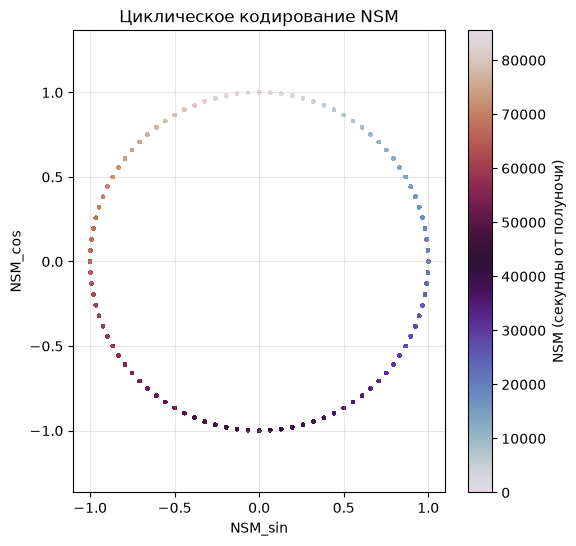

In [36]:
plt.figure(figsize=(6, 6))
sc = plt.scatter(df.features['NSM_sin'], df.features['NSM_cos'], c=df.features['NSM'], cmap='twilight', s=3)
plt.colorbar(sc, label='NSM (секунды от полуночи)')
plt.xlabel('NSM_sin')
plt.ylabel('NSM_cos')
plt.title('Циклическое кодирование NSM')
plt.axis('equal')
plt.grid(alpha=0.3)
plt.show()

Похожие преобразования нам понадобятся и для признака 'Day_of_week', с той разницей, что нам сначала нужно привести название дня к числу, а потом задать для него "координаты" на окружности

In [30]:
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_to_num = {d: i for i, d in enumerate(days_order)}

df.features['Day_of_week_num'] = df.features['Day_of_week'].map(day_to_num)
print(df.features[['Day_of_week', 'Day_of_week_num']].drop_duplicates().sort_values('Day_of_week_num'))

df.features['dow_sin'] = np.sin(2 * np.pi * df.features['Day_of_week_num'] / 7)
df.features['dow_cos'] = np.cos(2 * np.pi * df.features['Day_of_week_num'] / 7)

print("__________________")
print(f"Нет кода для cos дня: {df.features['dow_cos'].isna().sum()} шт.")
print(f"Нет кода для sin дня: {df.features['dow_sin'].isna().sum()} шт.")

    Day_of_week  Day_of_week_num
0        Monday                0
96      Tuesday                1
192   Wednesday                2
288    Thursday                3
384      Friday                4
480    Saturday                5
576      Sunday                6
__________________
Нет кода для cos дня: 0 шт.
Нет кода для sin дня: 0 шт.


Остался признак 'Week_status'. Этот признак переведем в число с помощью бинарной классификации

In [33]:
week_map = {'Weekday': 1, 'Weekend': 0}
df.features['WeekStatus_num'] = df.features['WeekStatus'].map(week_map)

print('Пропуски:', df.features['WeekStatus_num'].isna().sum())
print(df.features[['WeekStatus', 'WeekStatus_num']].drop_duplicates())

Пропуски: 0
    WeekStatus  WeekStatus_num
0      Weekday               1
480    Weekend               0


Посмотрим, что теперь у нас в датасете

In [40]:
df.features.info()

<class 'pandas.DataFrame'>
RangeIndex: 35040 entries, 0 to 35039
Data columns (total 15 columns):
 #   Column                                Non-Null Count  Dtype  
---  ------                                --------------  -----  
 0   Usage_kWh                             35040 non-null  float64
 1   Lagging_Current_Reactive.Power_kVarh  35040 non-null  float64
 2   Leading_Current_Reactive_Power_kVarh  35040 non-null  float64
 3   CO2(tCO2)                             35040 non-null  float64
 4   Lagging_Current_Power_Factor          35040 non-null  float64
 5   Leading_Current_Power_Factor          35040 non-null  float64
 6   NSM                                   35040 non-null  int64  
 7   WeekStatus                            35040 non-null  str    
 8   Day_of_week                           35040 non-null  str    
 9   NSM_sin                               35040 non-null  float64
 10  NSM_cos                               35040 non-null  float64
 11  Day_of_week_num           

Теперь мы можем собрать вектор переменных для обучения модели. В него войдут:

1. Lagging_Current_Reactive.Power_kVarh
2. Lagging_Current_Power_Factor
3. Leading_Current_Power_Factor
4. NSM_sin
5. NSM_cos
6. dow_sin
7. dow_cos
8. WeekStatus_num

Создадим вектор признаков для обучения наших моделей

In [41]:
features = [
    'Lagging_Current_Reactive.Power_kVarh',
    'Lagging_Current_Power_Factor',
    'Leading_Current_Power_Factor',
    'NSM_cos',
    'NSM_sin',
    'dow_sin',
    'dow_cos',
    'WeekStatus_num',
]

X = df.features[features]
y = df.targets['Load_Type']